# Day 2 — 글로벌 MLP · Chronos-2 · FVA 표 1차

| 항목 | 설정 |
|---|---|
| 원점 · 예측 기간 · 확정 | 2025-07-01부터 7일 간격 26개 · 7일 · 원점 전날 (Day 1 과 같음) |
| 1순위 지표 | **개소 단위 MASE** — 개소마다 7일 평균 절대 오차 ÷ 그 개소에서 1주 전 같은 요일 값(lag 7)이 2023-01-01~원점 전날 낸 평균 절대 오차, 원점·개소 평균 |
| 인력 | 분위수 모델은 q0.8 ÷ 2,000 (τ* = 60 ÷ (60+15)), 베이스라인은 규칙 그대로 |
| 글로벌 MLP | 입력 28일(log1p, 개소별 표준화) + 열림 표시 + 개소 원-핫 [+ 공변량] → 64 → 64 → 7일 × 분위수 4개(0.1·0.5·0.8·0.9), pinball 손실, Adam 1e-3, 배치 512, 검증 = 원점 직전 56일, 조기 종료 5에폭, 시드 0~4 |
| 학습 구간 | 2023-01-01 ~ 원점 57일 전 (표준화도 같은 구간) |
| Chronos-2 | 원점 전날까지 512일, 7일 한 번에, 분위수 9개. 공변량 = 공휴일·명절 연휴·마지막 수요일·정기 휴관 요일(df·future_df 양쪽) |

계산은 `python tools/run_day2.py` (CPU 8프로세스, 약 10분) 로 `outputs/day2/` 에 저장하고, 이 노트북은 그 결과를 읽어 표를 만듭니다.

In [1]:
import sys; sys.path.insert(0, 'src')
import pandas as pd, numpy as np
import hv, dl
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.3f}'.format)
from pathlib import Path
OUT = Path('outputs/day2')

v, w, c, s = hv.load()
assert hv.check_anchors(v, w, c)['일치'].all()
cal = hv.add_free_rule(hv.make_calendar())
panel = hv.build_panel(v, cal, s)
qden = hv.mase_denominators(panel)

## 1. 베이스라인과 서비스 수준 보정 (FVA 1·2행) — MASE 추가

In [2]:
m7 = hv.backtest(panel, hv.fc_mean7, name='mean7')
mult = hv.service_level_multiplier(panel, weeks=26, by='group')   # Day 1 검증 구간에서 고른 설정
base = {
    'B1 나이브': hv.backtest(panel, hv.fc_naive, name='B1 나이브'),
    'B2 계절 나이브(7일)': hv.backtest(panel, hv.fc_snaive7, name='B2 계절 나이브(7일)'),
    'F1 직전 7일 평균': m7.assign(model='F1 직전 7일 평균'),
    'F2 + 서비스 수준 보정': hv.apply_multiplier(m7, mult, by='group', name='F2 + 서비스 수준 보정'),
}
hv.summarize(pd.concat(base.values()), qden=qden)

,n,MASE,WAPE,적중률,부족비용,잉여비용,비용
model,,,,,,,
B1 나이브,3589,1.786,0.523,0.713,"770,566,800.000","177,851,400.000","948,418,200.000"
B2 계절 나이브(7일),3589,1.320,0.535,0.520,"746,800,500.000","192,512,925.000","939,313,425.000"
F1 직전 7일 평균,3589,1.333,0.480,0.600,"664,274,480.000","174,282,703.571","838,557,183.571"
F2 + 서비스 수준 보정,3589,1.333,0.480,0.810,"368,431,915.963","399,380,526.048","767,812,442.012"


## 2. 글로벌 MLP — FVA 3행부터 (시드 0~4)

행마다 앞 행의 정보에 하나씩 더합니다. 값은 시드 5개의 평균이고, `범위` 는 시드 5개 값의 최대 − 최소입니다.

In [3]:
raw = pd.read_parquet(OUT / 'mlp_raw.parquet')
VARIANT_LABEL = {
    'past': 'F3 MLP: 과거 관람객만',
    '+dow': 'F4 + 요일·정기 휴관 요일',
    '+holiday': 'F5 + 공휴일·명절 연휴',
    '+lastwed': 'F6 + 마지막 수요일',
    '+neighbor': 'F7 + 이웃 궁 휴관',
    '+rain_lag': 'F8 + 전날까지 비',
    '[완벽예보]+rain': '[완벽한 예보 가정] + 당일 비',
}
mlp = {}
for vk, lab in VARIANT_LABEL.items():
    r = raw[raw['variant'] == vk]
    mlp[lab] = {sd: hv.attach(panel, g.drop(columns=['variant', 'seed']), lab) for sd, g in r.groupby('seed')}
print('학습 에폭(최적) 분포:', raw.groupby('variant')['epochs'].describe()[['mean', 'min', 'max']].round(1).to_dict('index'))

학습 에폭(최적) 분포: {'+dow': {'mean': 15.0, 'min': 4.0, 'max': 35.0}, '+holiday': {'mean': 14.3, 'min': 3.0, 'max': 33.0}, '+lastwed': {'mean': 12.2, 'min': 3.0, 'max': 22.0}, '+neighbor': {'mean': 12.2, 'min': 4.0, 'max': 22.0}, '+rain_lag': {'mean': 11.0, 'min': 5.0, 'max': 31.0}, '[완벽예보]+rain': {'mean': 8.7, 'min': 2.0, 'max': 20.0}, 'past': {'mean': 14.2, 'min': 3.0, 'max': 32.0}}


In [4]:
def seed_table(runs, by=None):
    per = pd.concat([hv.summarize(bt, by=by, qden=qden).assign(seed=sd) for sd, bt in runs.items()])
    keys = [by] if by else []
    g = per.reset_index().groupby(keys + ['model'])
    mean = g[['MASE', 'WAPE', '포함률(80%)', '적중률', '비용']].mean()
    mean['MASE 범위'] = g['MASE'].agg(lambda x: x.max() - x.min())
    mean['비용 범위'] = g['비용'].agg(lambda x: x.max() - x.min())
    return mean, per

rows, per_seed = [], {}
for lab, runs in mlp.items():
    m, per = seed_table(runs)
    rows.append(m); per_seed[lab] = per.set_index('seed')['비용']
mlp_tab = pd.concat(rows)
mlp_tab

,MASE,WAPE,포함률(80%),적중률,비용,MASE 범위,비용 범위
model,,,,,,,
F3 MLP: 과거 관람객만,0.999,0.392,0.759,0.790,"697,171,410.541",0.026,"33,910,154.652"
F4 + 요일·정기 휴관 요일,0.989,0.391,0.757,0.782,"691,979,212.258",0.013,"51,411,953.547"
F5 + 공휴일·명절 연휴,0.914,0.342,0.764,0.787,"556,779,771.953",0.046,"48,168,470.580"
F6 + 마지막 수요일,0.931,0.348,0.760,0.780,"566,332,000.448",0.021,"22,536,627.353"
F7 + 이웃 궁 휴관,0.919,0.340,0.756,0.778,"550,690,490.198",0.018,"22,559,365.661"
F8 + 전날까지 비,0.943,0.351,0.726,0.770,"589,845,849.405",0.029,"41,390,108.798"
[완벽한 예보 가정] + 당일 비,0.941,0.350,0.698,0.754,"586,674,582.362",0.035,"41,913,813.281"


## 3. Chronos-2 — 제로샷 / + 공변량

In [5]:
chz = pd.read_parquet(OUT / 'chronos_zs.parquet')
chc = pd.read_parquet(OUT / 'chronos_cov.parquet')
ch = pd.concat([chz, chc])
ch_tab = hv.summarize(ch, qden=qden)
# 공개일(2025-10-17) 이전 원점: 채점 7일이 공개일 전에 끝나면 사전학습 자료와 겹쳤을 수 있다
ch['공개일 기준'] = np.where(ch['origin'] + pd.Timedelta(days=6) < dl.CHRONOS_RELEASE, '공개일 전(겹침 가능)', '공개일 후')
display(ch_tab)
hv.summarize(ch, by='공개일 기준', qden=qden)[['n', 'MASE', 'WAPE', '포함률(80%)', '적중률', '비용']]

,n,MASE,WAPE,포함률(80%),적중률,부족비용,잉여비용,비용
model,,,,,,,,
Chronos-2 + 공변량,3589,0.936,0.340,0.741,0.828,"339,542,359.933","225,948,534.730","565,490,894.663"
Chronos-2 제로샷,3589,0.949,0.354,0.775,0.838,"416,338,489.524","210,275,746.550","626,614,236.073"


n  MASE  WAPE  포함률(80%)   적중률              비용
공개일 기준       model                                                            
공개일 전(겹침 가능) Chronos-2 + 공변량  2070 0.892 0.322     0.753 0.811 278,135,957.473
             Chronos-2 제로샷    2070 0.959 0.388     0.777 0.807 363,127,996.669
공개일 후        Chronos-2 + 공변량  1519 0.995 0.359     0.724 0.852 287,354,937.190
             Chronos-2 제로샷    1519 0.934 0.319     0.772 0.880 263,486,239.404

## 4. FVA 표 1차 (요구사항 6)

1순위 지표 MASE, 비용(원), 앞 행 대비 비용 변화. MLP 행은 시드 5개 평균, `5시드 모두 앞 행보다 비용 ↓` 는 같은 시드끼리 비교한 결과입니다.

In [6]:
b = hv.summarize(pd.concat([base['F1 직전 7일 평균'], base['F2 + 서비스 수준 보정']]), qden=qden)
b['MASE 범위'] = 0.0; b['비용 범위'] = 0.0
fva = pd.concat([b.reindex(columns=mlp_tab.columns), mlp_tab, ch_tab.reindex(columns=mlp_tab.columns)])  # 베이스라인은 분위수가 없어 포함률 빈칸
fva['앞 행 대비 비용 변화(원)'] = fva['비용'].diff()
order = list(fva.index)
labs = list(VARIANT_LABEL.values())
same_dir = {labs[i]: bool((per_seed[labs[i]] < per_seed[labs[i - 1]]).all()) for i in range(1, len(labs))}
fva['5시드 모두 앞 행보다 비용 ↓'] = pd.Series(same_dir)
fva.loc[ch_tab.index, '앞 행 대비 비용 변화(원)'] = np.nan
fva['직전 7일 평균 대비 절감(원)'] = fva.loc['F1 직전 7일 평균', '비용'] - fva['비용']
fva_out = fva.copy()
for col in ['비용', '비용 범위', '앞 행 대비 비용 변화(원)', '직전 7일 평균 대비 절감(원)']:
    fva_out[col] = fva_out[col].round(0)
fva_out.to_csv(OUT / 'fva_v1.csv', encoding='utf-8-sig')
fva_out

,MASE,WAPE,포함률(80%),적중률,비용,MASE 범위,비용 범위,앞 행 대비 비용 변화(원),5시드 모두 앞 행보다 비용 ↓,직전 7일 평균 대비 절감(원)
model,,,,,,,,,,
F1 직전 7일 평균,1.333,0.480,NaN,0.600,"838,557,184.000",0.000,0.000,NaN,NaN,0.000
F2 + 서비스 수준 보정,1.333,0.480,NaN,0.810,"767,812,442.000",0.000,0.000,"-70,744,742.000",NaN,"70,744,742.000"
F3 MLP: 과거 관람객만,0.999,0.392,0.759,0.790,"697,171,411.000",0.026,"33,910,155.000","-70,641,031.000",NaN,"141,385,773.000"
F4 + 요일·정기 휴관 요일,0.989,0.391,0.757,0.782,"691,979,212.000",0.013,"51,411,954.000","-5,192,198.000",False,"146,577,971.000"
F5 + 공휴일·명절 연휴,0.914,0.342,0.764,0.787,"556,779,772.000",0.046,"48,168,471.000","-135,199,440.000",True,"281,777,412.000"
F6 + 마지막 수요일,0.931,0.348,0.760,0.780,"566,332,000.000",0.021,"22,536,627.000","9,552,228.000",False,"272,225,183.000"
F7 + 이웃 궁 휴관,0.919,0.340,0.756,0.778,"550,690,490.000",0.018,"22,559,366.000","-15,641,510.000",True,"287,866,693.000"
F8 + 전날까지 비,0.943,0.351,0.726,0.770,"589,845,849.000",0.029,"41,390,109.000","39,155,359.000",False,"248,711,334.000"
[완벽한 예보 가정] + 당일 비,0.941,0.350,0.698,0.754,"586,674,582.000",0.035,"41,913,813.000","-3,171,267.000",False,"251,882,601.000"


## 5. 주 유형별 — 특별일(공휴일·무료 개방일 규칙) 있는 주 / 없는 주

수업 규칙: 평가표를 평균 하나로 정하지 않고 주 유형으로 나눕니다. 26개 원점 가운데 특별일 있는 주의 수도 함께 봅니다.

In [7]:
def by_week(bt):
    bt = bt.assign(주유형=hv.week_type(bt))
    return hv.summarize(bt, by='주유형', qden=qden)

pick = ['F4 + 요일·정기 휴관 요일', 'F6 + 마지막 수요일', 'F8 + 전날까지 비']
frames = [base['B2 계절 나이브(7일)'], base['F1 직전 7일 평균'], base['F2 + 서비스 수준 보정']] + \
         [pd.concat([bt.assign(seed=sd) for sd, bt in mlp[p].items()]) for p in pick] + [chz, chc]
wk = []
for f in frames:
    if 'seed' in f:
        t = pd.concat([by_week(g).assign(seed=sd) for sd, g in f.groupby('seed')]).reset_index().groupby(['주유형', 'model']).mean(numeric_only=True).drop(columns='seed')
    else:
        t = by_week(f)
    wk.append(t)
wk = pd.concat(wk)
print('원점 수:', hv.backtest(panel, hv.fc_naive).assign(주유형=lambda d: hv.week_type(d)).groupby('주유형')['origin'].nunique().to_dict())
wk[['MASE', 'WAPE', '포함률(80%)', '적중률', '비용']].unstack('주유형')

원점 수: {'특별일 없는 주': 17, '특별일 있는 주': 9}


MASE              WAPE          포함률(80%)               적중률                       비용                
주유형              특별일 없는 주 특별일 있는 주 특별일 없는 주 특별일 있는 주 특별일 없는 주 특별일 있는 주 특별일 없는 주 특별일 있는 주        특별일 없는 주        특별일 있는 주
model                                                                                                                   
B2 계절 나이브(7일)       1.130    1.679    0.516    0.561      NaN      NaN    0.569    0.427 396,142,350.000 543,171,075.000
Chronos-2 + 공변량     0.718    1.347    0.316    0.373    0.755    0.713    0.860    0.769 270,880,581.779 294,610,312.884
Chronos-2 제로샷       0.685    1.446    0.283    0.451    0.812    0.706    0.889    0.742 244,891,585.367 381,722,650.707
F1 직전 7일 평균         1.199    1.585    0.471    0.493      NaN      NaN    0.671    0.467 350,099,794.286 488,457,389.286
F2 + 서비스 수준 보정      1.199    1.585    0.471    0.493      NaN      NaN    0.871    0.695 383,043,338.195 384,769,103.816
F4 + 요일·정기 휴관 요일    0.702    1.531    0.315    0.494    0.801    0.673    0.829    0.695 282,385,597.961 409,593,614.297
F6 + 마지막 수요일        0.693    1.379    0.308    0.402    0.776    0.731    0.779    0.782 283,577,685.639 282,754,314.808
F8 + 전날까지 비         0.698    1.405    0.309    0.409    0.741    0.699    0.770    0.769 297,680,686.776 292,165,162.628

## 6. 날짜 유형 · 개소 유형별 (주제 1: 무료 개방일)

In [8]:
def day_type(d):
    return np.select([d['is_free_rule'] == 1, d['is_holiday'] == 1, d['is_offday'] == 1], ['무료개방(규칙)', '공휴일', '주말'], '평일')

def typed(bt, key):
    bt = bt.assign(날짜유형=day_type(bt))
    return hv.summarize(bt, by=key, qden=qden)[['WAPE', '적중률', '비용']]

best_mlp = pd.concat([bt.assign(seed=sd) for sd, bt in mlp['F6 + 마지막 수요일'].items()])
best_mlp = best_mlp[best_mlp['seed'] == 0]
cmp = pd.concat([base['F1 직전 7일 평균'], base['F2 + 서비스 수준 보정'], best_mlp, chc])
display(typed(cmp, '날짜유형').unstack('model'))
typed(cmp, 'group').unstack('model')

WAPE                                                     적중률                                                      비용                                                
model    Chronos-2 + 공변량 F1 직전 7일 평균 F2 + 서비스 수준 보정 F6 + 마지막 수요일 Chronos-2 + 공변량 F1 직전 7일 평균 F2 + 서비스 수준 보정 F6 + 마지막 수요일 Chronos-2 + 공변량     F1 직전 7일 평균  F2 + 서비스 수준 보정    F6 + 마지막 수요일
날짜유형                                                                                                                                                                                    
공휴일                0.317       0.289          0.289        0.307           0.630       0.109          0.522        0.609   4,980,986.782   8,182,862.500   4,028,689.052   4,408,067.534
무료개방(규칙)           0.434       0.589          0.589        0.469           0.495       0.276          0.440        0.705 174,332,096.453 314,228,721.429 242,152,583.893 151,445,557.898
주말                 0.312       0.385          0.385        0.320           0.851       0.303          0.634        0.777 180,715,768.968 274,403,143.571 206,887,185.875 186,513,531.097
평일                 0.323       0.513          0.513        0.315           0.864       0.814          0.959        0.792 205,462,043.557 241,742,456.071 314,743,983.191 218,502,376.244

WAPE                                                     적중률                                                      비용                                                
model Chronos-2 + 공변량 F1 직전 7일 평균 F2 + 서비스 수준 보정 F6 + 마지막 수요일 Chronos-2 + 공변량 F1 직전 7일 평균 F2 + 서비스 수준 보정 F6 + 마지막 수요일 Chronos-2 + 공변량     F1 직전 7일 평균  F2 + 서비스 수준 보정    F6 + 마지막 수요일
group                                                                                                                                                                                
궁               0.326       0.446          0.446        0.331           0.757       0.549          0.803        0.730 431,093,787.067 625,593,067.857 566,710,024.476 426,001,207.285
왕릉              0.381       0.540          0.540        0.381           0.847       0.612          0.812        0.793  91,434,598.734 139,417,249.643 130,040,025.092  89,116,851.244
종묘              0.457       0.868          0.868        0.505           0.783       0.599          0.803        0.720  42,962,509.959  73,546,866.071  71,062,392.444  45,751,474.244

### 원점별 비용과 계절 나이브보다 MASE 가 낮은 개소 비율

,Chronos-2 + 공변량,F1 직전 7일 평균,F2 + 서비스 수준 보정,F6 + 마지막 수요일
origin,,,,
2025-07-01,1.000,0.260,0.260,0.960
2025-07-08,0.480,0.170,0.170,0.700
2025-07-15,0.480,0.090,0.090,0.610
2025-07-22,0.830,0.870,0.870,0.780
2025-07-29,0.780,0.260,0.260,0.700
2025-08-05,0.960,0.300,0.300,0.740
2025-08-12,0.480,0.040,0.040,0.300
2025-08-19,0.780,0.700,0.700,0.960
2025-08-26,0.570,0.170,0.170,0.570


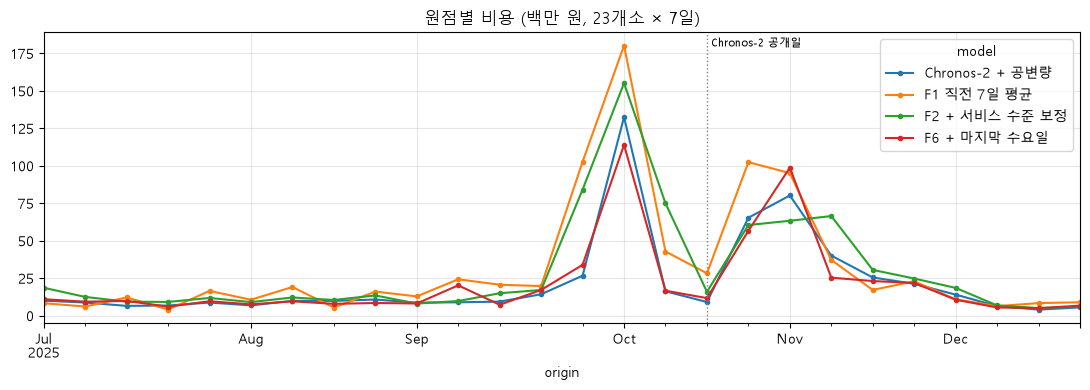

In [9]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'; plt.rcParams['axes.unicode_minus'] = False
d = hv.add_cost(cmp[cmp['status'] == 'open'])
po = d.groupby(['origin', 'model'])['cost'].sum().unstack() / 1e6
ax = po.plot(figsize=(11, 4), marker='o', ms=3)
ax.axvline(dl.CHRONOS_RELEASE, color='gray', ls=':', lw=1); ax.text(dl.CHRONOS_RELEASE, ax.get_ylim()[1] * .95, ' Chronos-2 공개일', fontsize=8)
ax.set_title('원점별 비용 (백만 원, 23개소 × 7일)'); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT / 'per_origin_cost.png', dpi=150)
po.round(1).to_csv(OUT / 'per_origin_cost.csv', encoding='utf-8-sig')

def site_mase(bt):
    x = bt[bt['status'] == 'open'].assign(ae=lambda d: (d['y'] - d['yhat']).abs())
    return x.groupby(['origin', 'site'])['ae'].mean()
sn = site_mase(base['B2 계절 나이브(7일)'])
beat = pd.DataFrame({m: (site_mase(g) < sn.reindex(site_mase(g).index)).groupby('origin').mean()
                     for m, g in cmp.groupby('model')})
beat.round(2)

## Day 2 결론 · Day 3 할 일

**FVA (시드 5개 평균, 원점 26개 × 23개소, 기본 가정)**

- F1 직전 7일 평균 8.39억 → F2 서비스 수준 보정 7.68억 → F3 MLP(과거만) 6.97억 → **F5 + 공휴일·명절 5.57억(−1.35억, 5시드 모두 ↓)** → F7 + 이웃 휴관 **5.51억**(직전 7일 평균 대비 **−2.88억**)
- 가장 큰 한 걸음은 **공휴일·명절 연휴** 정보. MASE 0.989 → 0.914 (시드 범위 0.046 보다 큼)
- **요일·정기 휴관**(F4), **마지막 수요일**(F6, 전체 평균), **이웃 휴관**(F7)은 MASE 차이가 시드 범위 안 → 전체 평균으로는 「차이 없음」. 단 주 유형별로 보면 마지막 수요일은 **특별일 있는 주** MASE 1.531(F4) → 1.379(F6), 비용 4.10억 → 2.83억 — 효과가 특별일 주에만 몰려 전체 평균에 묻힘
- **비**: 전날까지 비(F8)는 비용 +0.39억(5시드 모두 ↓ 아님), 당일 비 완벽 예보도 개선 없음 → 날씨는 최종 모형에서 뺀다(격자 강수의 품질 한계와 일치)

**Chronos-2**

- 제로샷 6.27억, + 공변량 5.65억 — 최선 MLP(5.51억)와 비슷한 수준
- 공개일(2025-10-17) 전 원점에서는 + 공변량이 크게 좋고(MASE 0.892), 공개일 후에는 제로샷보다 나쁨(0.995 vs 0.934) → 공개일 전 점수는 사전학습 자료와 겹쳤을 수 있어 그대로 믿지 않는다
- 특별일 없는 주에는 제로샷이 MASE 0.685 로 가장 낮음(수업 결과와 같은 모양)

**적중률·포함률**: MLP 적중률 0.78~0.79(목표 0.80), 80% 포함률 0.76 — 위쪽으로 벗어나는 날이 조금 많음. 무료 개방일 적중률은 F6 0.71, Chronos-2 + 공변량 0.50

**Day 3**

1. 최종 후보: F7(MLP + 공휴일·명절·마지막 수요일·이웃 휴관), Chronos-2 + 공변량, 둘의 앙상블 — 공개일 후 원점·시드 범위로 판정
2. 근무표 확정 시점 2종(원점 전날 vs 1주 전) 비용 비교 — `dl.fit_predict_mlp` 출력 길이 확장 필요
3. 유형별 지표·적중률 확정, 인력이 가장 많이 모자란 10건 → 원인 확인(공지)
4. 마지막 수요일 효과가 왜 전체 평균에서 안 보이는지: 무료 개방일 손실 가중치 / 학습 구간을 2015~2019 궁 자료까지 늘리는 안
